In [11]:
#1\importing libraries 
import pandas as pd 
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree 
import matplotlib.pyplot as plt 

In [12]:
#2\loading the dataset 
df=pd.read_csv('jobs_dataset.csv') #read the file
print(df.head()) #show frist 5 rows
print("shape:",df.shape)

           company  rating             location  \
0           Google     4.3        San Bruno, CA   
1           BAXTER     3.7  Milwaukee, WI 53214   
2             Meta     4.2          Redmond, WA   
3             Meta     4.2   Bellevue, WA 98005   
4  Lockheed Martin     4.0    Shelton, CT 06484   

                                        positionName  \
0    Senior Data Scientist, Research, YouTube Search   
1                Senior AI Engineer - Data Scientist   
2         Audio Software Engineer, Applied Scientist   
3                Software Engineer, Machine Learning   
4  AI / Machine Learning Research Engineer (early...   

                                         description  \
0  Note: By applying to this position you will ha...   
1  This is where you save and sustain lives\n\nAt...   
2  Redmond, WA • + 2 more•Full Time\nMessenger\nM...   
3  Bellevue, WA • Full Time\nMeta\nSoftware Engin...   
4  Job ID: 694362BR\nDate posted: May. 22, 2025\n...   

                   

In [14]:
#3\data cleaning
df=df.dropna(subset=['salary']) #remove rows with no salary
df['salary_num']=(df['salary'].str.extract(r'\$(\d+,?\d*)')[0].str.replace(',','').astype(float)) #convert salary text to a number
df=df.dropna(subset=['salary_num']).copy() #remove rows where extraction failed

In [17]:
#4\Define Features and target 
x_text=df[['company','rating','location','positionName']].copy() #input columns
y=df['salary_num'] #target column

In [19]:
#5\handle missing value
x_text['rating']=x_text['rating'].fillna(x_text['rating'].median()) #fill missing ratings with the median

In [21]:
#6\one_hot encoding
x=pd.get_dummies(x_text,columns=['company','location','positionName'],drop_first=True) #convert text columns to 0\1 columns
print("features shape:",x.shape)

features shape: (506, 889)


In [23]:
#7\build and train model
model =DecisionTreeRegressor(max_depth=5,random_state=42) #create the model
model.fit(x,y) #train it on x and y 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [24]:
#8\predicting 
predictions =model.predict(x.head(5)) #predict salaries
print("Model predictions:",predictions)
print("Real salaries:",y.head(5).values)

Model predictions: [1.48939622e+05 1.25663323e+05 7.00000000e+01 1.01703000e+05
 1.48939622e+05]
Real salaries: [1.6600e+05 1.1200e+05 7.0000e+01 2.0335e+05 1.9700e+05]


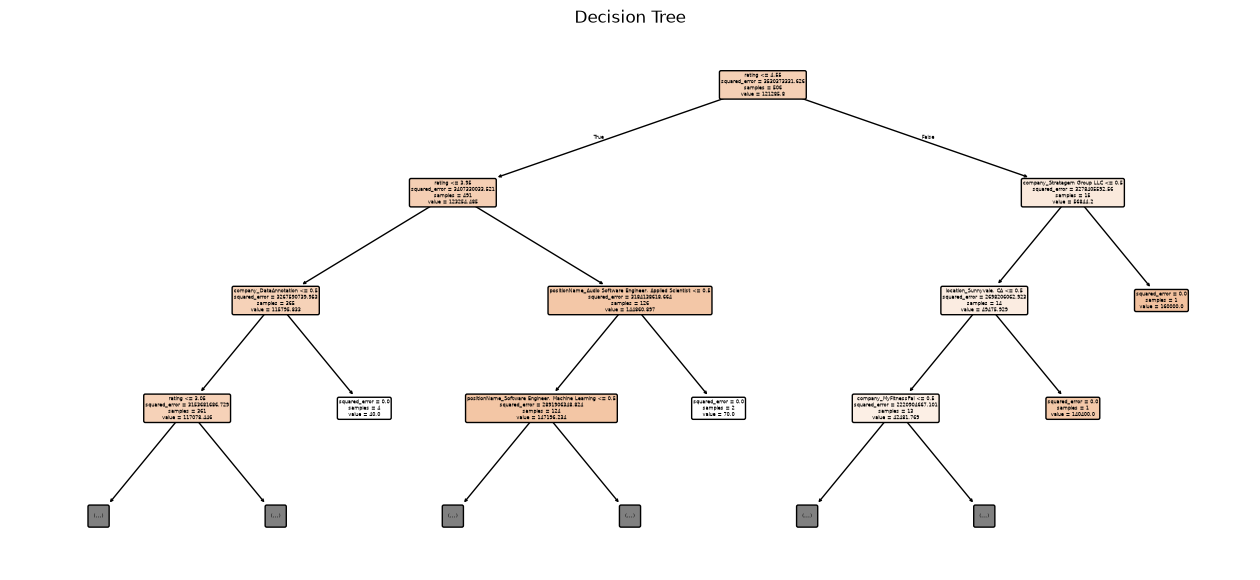

In [25]:
#9\visualize the decision tree
plt.figure(figsize=(16,7))  #picture size
plot_tree(model,max_depth=3,feature_names=x.columns,filled=True,rounded=True) #drow the dicision tree
plt.title("Decision Tree") #add a title
plt.show() 